In [16]:
import pandas as pd 
import numpy as np 
import sklearn 
import matplotlib

print ("pandas:", pd.__version__) 
print ("numpy:", np.__version__) 
print ("sklearn:", sklearn.__version__) 

pandas: 2.2.2
numpy: 1.26.4
sklearn: 1.5.1


In [18]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing (as_frame = True) 
df = data.frame
print (df.shape) 
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [20]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [22]:
df.describe() 

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [24]:
df.isnull().sum() 

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [26]:
(df["MedHouseVal"] >= 5).sum() 

992

In [28]:
(df["AveRooms"] > 20).sum() 

69

In [30]:
(df["AveOccup"] > 20).sum() 

10

In [32]:
df_clean = df[
    (df["AveRooms"] <= 20) 
    & (df["AveOccup"] <= 20) 
    & (df["MedHouseVal"] < 5) 
].copy() 

print (df.shape, df_clean.shape) 

(20640, 9) (19571, 9)


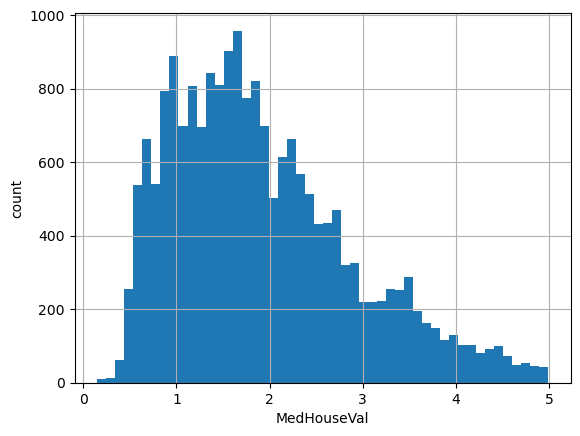

In [34]:
import matplotlib.pyplot as plt 

df_clean["MedHouseVal"].hist(bins=50) 
plt.xlabel("MedHouseVal") 
plt.ylabel("count") 
plt.show() 

In [36]:
df_clean.corr()["MedHouseVal"].sort_values(ascending = False) 

MedHouseVal    1.000000
MedInc         0.648224
AveRooms       0.203214
HouseAge       0.064915
Population     0.012625
Longitude     -0.045626
AveBedrms     -0.105807
Latitude      -0.149015
AveOccup      -0.225566
Name: MedHouseVal, dtype: float64

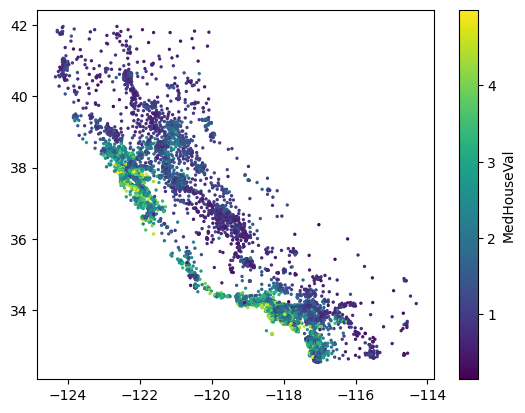

In [38]:
plt.scatter(df_clean["Longitude"], df_clean["Latitude"],
           c = df_clean["MedHouseVal"], s = 2, cmap = "viridis") 
plt.colorbar(label = "MedHouseVal") 
plt.show() 

In [40]:
from sklearn.model_selection import train_test_split 

X = df_clean.drop("MedHouseVal", axis=1) 
y = df_clean["MedHouseVal"] 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) 

print(X_train.shape, X_test.shape) 

(15656, 8) (3915, 8)


In [42]:
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, r2_score 
import numpy as np 

model = LinearRegression() 
model.fit(X_train, y_train) 

y_pred = model.predict(X_test) 

rmse = np.sqrt(mean_squared_error(y_test, y_pred)) 
r2 = r2_score(y_test, y_pred) 

print("RMSE:", rmse) 
print("R2:", r2) 

RMSE: 0.6159913990536731
R2: 0.609192963463479


In [46]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("RMSE:", rmse_rf)
print("R2:", r2_rf)

RMSE: 0.47068725706724707
R2: 0.7718197982750784


In [48]:
import pandas as pd

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False))

MedInc        0.458143
AveOccup      0.140556
Longitude     0.116626
Latitude      0.107400
AveRooms      0.056135
HouseAge      0.053385
Population    0.035961
AveBedrms     0.031794
dtype: float64


In [50]:
print("Train R2:", r2_score(y_train, rf.predict(X_train)))
print("Test R2:", r2_score(y_test, rf.predict(X_test)))

Train R2: 0.9696347631531754
Test R2: 0.7718197982750784


In [52]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": [0.5, 0.7, 1.0],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    verbose=1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)

best_rf = search.best_estimator_
y_pred_best = best_rf.predict(X_test)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R2:", r2_score(y_test, y_pred_best))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': None}
RMSE: 0.4658471349613797
R2: 0.7764884677303154


In [58]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(random_state=42)
hgb.fit(X_train, y_train)

y_pred_hgb = hgb.predict(X_test)

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_hgb)))
print("R2:", r2_score(y_test, y_pred_hgb))

RMSE: 0.438655037394764
R2: 0.8018202299171806


In [60]:
print("Train R2 (hgb):", r2_score(y_train, hgb.predict(X_train)))

hgb2 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)
hgb2.fit(X_train, y_train)

y_pred2 = hgb2.predict(X_test)
print("Iterations used:", hgb2.n_iter_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred2)))
print("R2:", r2_score(y_test, y_pred2))

Train R2 (hgb): 0.8624235526489737
Iterations used: 500
RMSE: 0.42567850222296266
R2: 0.8133721238340401


In [62]:
hgb3 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=30,
    random_state=42,
)
hgb3.fit(X_train, y_train)

y_pred3 = hgb3.predict(X_test)
print("Iterations used:", hgb3.n_iter_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred3)))
print("R2:", r2_score(y_test, y_pred3))

Iterations used: 855
RMSE: 0.4230905764640656
R2: 0.8156344459495


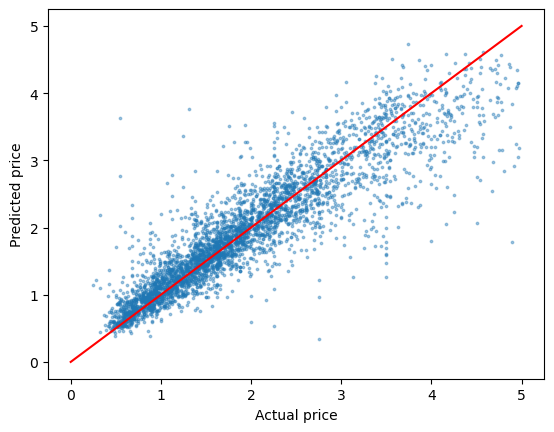

['house_price_model.joblib']

In [64]:
import joblib

plt.scatter(y_test, y_pred3, s=3, alpha=0.4)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.show()

joblib.dump(hgb3, "house_price_model.joblib")

In [66]:
loaded = joblib.load("house_price_model.joblib")

sample = X_test.iloc[[0]]
print(sample)
print("Predicted:", loaded.predict(sample)[0])
print("Actual:", y_test.iloc[0])

      MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
6414  2.8352      20.0  4.502688   1.116935      1816.0   2.44086     34.14   

      Longitude  
6414    -118.01  
Predicted: 1.9036872305209722
Actual: 1.617


In [1]:
import numpy as np
import joblib
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = fetch_california_housing(as_frame=True).frame
df_clean = df[
    (df["AveRooms"] <= 20)
    & (df["AveOccup"] <= 20)
    & (df["MedHouseVal"] < 5)
].copy()

X = df_clean.drop("MedHouseVal", axis=1)
y = df_clean["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

hgb3 = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=30,
    random_state=42,
)
hgb3.fit(X_train, y_train)

pred = hgb3.predict(X_test)
print("Iterations used:", hgb3.n_iter_)
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2:", r2_score(y_test, pred))

joblib.dump(hgb3, "house_price_model.joblib")

C:\Users\_mdsol\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\_mdsol\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\_mdsol\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\_mdsol\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\_mdsol\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

Iterations used: 855
RMSE: 0.4230905764640656
R2: 0.8156344459495


['house_price_model.joblib']